# Importing Libraries


In [1]:
import pandas as pd
import tqdm as tqdm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path



# Opening an Image for Testing




number of images:  10000


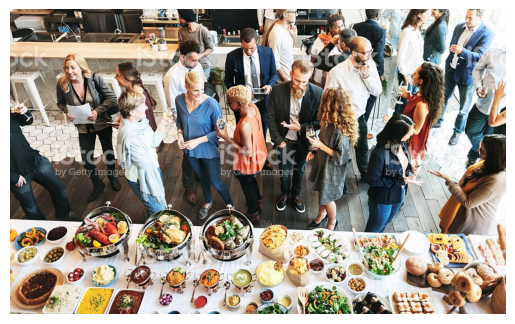

10000


In [2]:
folder = Path(r"D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\Images")

image_path = list(folder.glob("*.jpg"))
print("number of images: ", len(image_path))



img = Image.open(folder / "273271,1a0d6000b9e1f5b7.jpg")

plt.imshow(img)

plt.axis("off")
plt.show()
print(len(image_path))


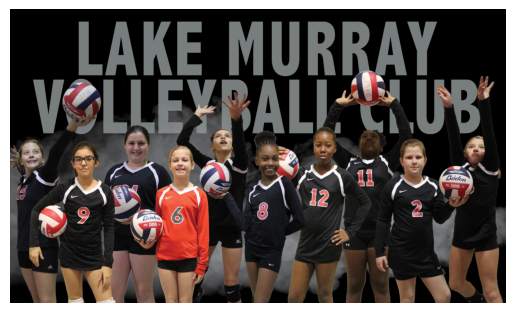

In [3]:
imagi = Image.open(image_path[0]).convert("RGB")
plt.imshow(imagi)
plt.axis("off")
plt.show()

# Loading CSV File

In [4]:
df = pd.read_csv(r"D:\COLLEGE_ML_PROJECT_VLM\Ashwarya_Yuvraj_COREVQA.csv")

df.head()
df.isnull().sum()
df["image_id"].nunique()
df["question"].nunique()
df["image_id"].unique()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5608 entries, 0 to 5607
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   image_id  5608 non-null   str  
 1   question  5608 non-null   str  
 2   answer    5608 non-null   bool 
dtypes: bool(1), str(2)
memory usage: 1.1 MB


# Data Exploration and Analysis


## Creating new Column in Data Frame

In [5]:
image_dict = {}

for path in image_path:
    image_id = path.name
    
    image_dict[image_id] = str(path)

In [6]:
df_copy = df.copy()

df_copy["image_path"] = df_copy["image_id"].map(image_dict)

df_copy["image_path"].isnull().sum()

df_copy['valid_image_path'] = df_copy["image_path"].dropna()

df_copy.head()


,image_id,question,answer,image_path,valid_image_path
0,"273275,ccb840000d91e6f7.jpg",Although at least three people are wearing gla...,True,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...
1,"273271,20c260008043e030.jpg",Although four people are sitting upright on th...,True,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...
2,"273271,2fb52000b8957210.jpg",The player with the basketball is looking towa...,False,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...
3,"273275,b697c0009c79a567.jpg",The man holding the sign with a painted flag i...,False,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...
4,"273275,a4dba00020612aa5.jpg",Only one person in the group is jumping while ...,False,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...


In [13]:
print(f"Total Rows: {len(df_copy)}")
print(f"Matched : {df_copy['image_path'].notna().sum()}")
print(f"Unmatched : {df_copy['image_path'].isna().sum()}")

Total Rows: 5608
Matched : 5608
Unmatched : 0


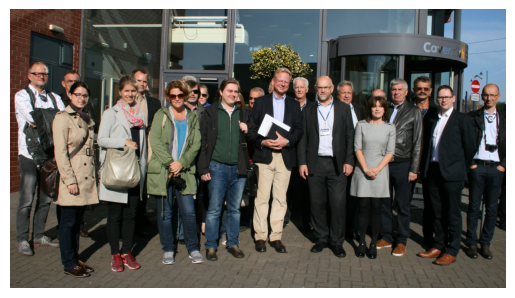

273275,ccb840000d91e6f7.jpg
Although at least three people are wearing glasses and one individual holds a camera, there is not a single person in the group with crossed arms or visibly wearing a hat.
<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=3347x1880 at 0x21BD6797D90>


In [14]:
img = Image.open(df_copy.loc[0, "image_path"])

plt.imshow(img)
plt.axis("off")
plt.show()

print(df_copy.loc[0, "image_id"])
print(df_copy.loc[0, "question"])
print(img)

In [15]:
print(f"Image Format : {img.format}")
print(f"Image Size : {img.size}")
print(f"Image Mode : {img.mode}")

Image Format : JPEG
Image Size : (3347, 1880)
Image Mode : RGB


In [16]:
print(df_copy.shape)
print(df_copy.columns)
print(df_copy.info)
print(df_copy.head())

(5608, 5)
Index(['image_id', 'question', 'answer', 'image_path', 'valid_image_path'], dtype='str')
<bound method DataFrame.info of                          image_id  \
0     273275,ccb840000d91e6f7.jpg   
1     273271,20c260008043e030.jpg   
2     273271,2fb52000b8957210.jpg   
3     273275,b697c0009c79a567.jpg   
4     273275,a4dba00020612aa5.jpg   
...                           ...   
5603  273278,f81610005f31500d.jpg   
5604  282555,a9eb500020c461ae.jpg   
5605   282555,6ce9000c96d59c9.jpg   
5606  273278,a0654000845ad101.jpg   
5607  273278,d870c000ce317ac9.jpg   

                                               question  answer  \
0     Although at least three people are wearing gla...    True   
1     Although four people are sitting upright on th...    True   
2     The player with the basketball is looking towa...   False   
3     The man holding the sign with a painted flag i...   False   
4     Only one person in the group is jumping while ...   False   
...                   

Image Id : 273275,ccb840000d91e6f7.jpg
Question : Although at least three people are wearing glasses and one individual holds a camera, there is not a single person in the group with crossed arms or visibly wearing a hat.
Answer : True


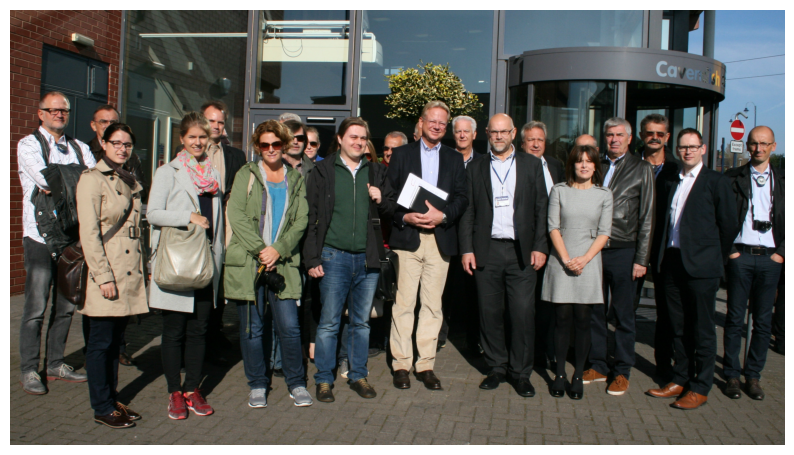

Image Id : 273271,20c260008043e030.jpg
Question : Although four people are sitting upright on the couch and at least two are wearing glasses, only the person lying across their laps is both barefoot and laughing with her head tilted back.
Answer : True


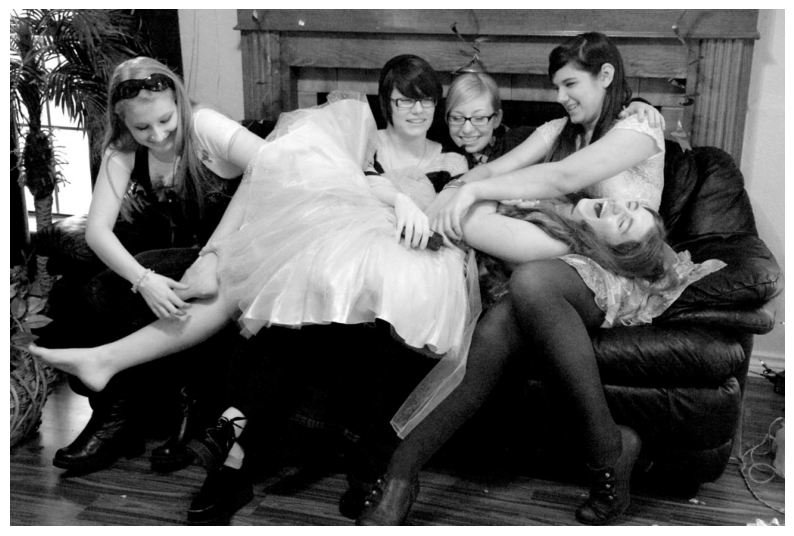

Image Id : 273271,2fb52000b8957210.jpg
Question : The player with the basketball is looking toward a teammate who is positioned outside the three-point line, suggesting they're about to make a long pass rather than attempt a shot.
Answer : False


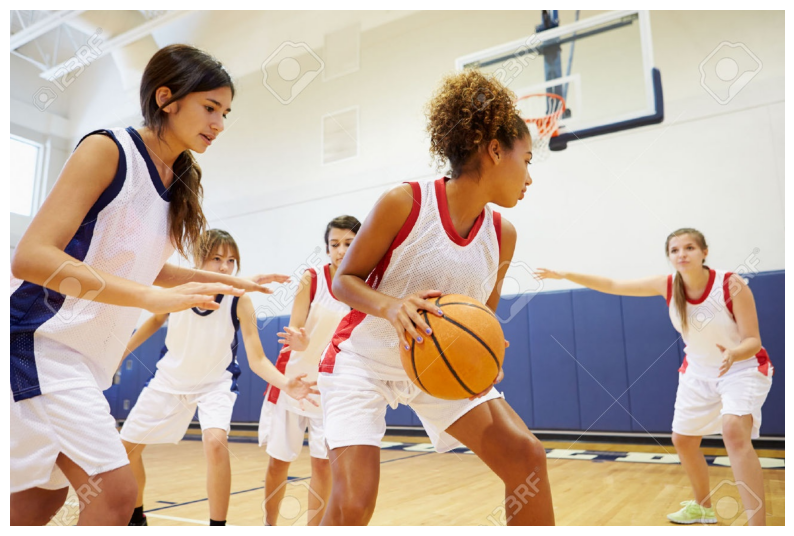

In [17]:
for i in range(3):
    img = Image.open(df_copy.loc[i, "image_path"]).convert("RGB")
    
    print(f"Image Id : {df_copy.loc[i, 'image_id']}")
    print(f"Question : {df_copy.loc[i, 'question']}")
    print(f"Answer : {df_copy.loc[i, 'answer']}")
    
    plt.figure(figsize = (10, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

## Analysing the Data

In [18]:
print(df_copy["valid_image_path"].apply(lambda x: Path(x).exists()).value_counts())

print(df_copy["answer"].value_counts(normalize = True)*100)

valid_image_path
True    5608
Name: count, dtype: int64
answer
False    72.075606
True     27.924394
Name: proportion, dtype: float64


In [19]:
from statistics import mean


widths = []
heights = []

for path in df_copy["valid_image_path"]:
    img = Image.open(path)

    width, height = img.size

    widths.append(width)
    heights.append(height)
    
    
avg_width = mean(widths)
avg_heights = mean(heights)

print(f"average Width :  {avg_width}")
print(f"Average Height : {avg_heights}")

print(f"Minimum Width : {min(widths)}")
print(f"Minimum Height : {min(heights)}")
print(f"Maximum Width : {max(widths)}")
print(f"Maximum Height : {max(heights)}")







average Width :  1351.0763195435093
Average Height : 961.722539229672
Minimum Width : 400
Minimum Height : 343
Maximum Width : 9931
Maximum Height : 5333


In [20]:
df_copy["question_length"] = df_copy["question"].apply(len)

print(df_copy["question_length"].describe())

count    5608.000000
mean      169.981990
std        41.967225
min        48.000000
25%       139.000000
50%       173.000000
75%       198.000000
max       354.000000
Name: question_length, dtype: float64


In [21]:
for i in range(5):
    print(f"Question : {df_copy.loc[i, 'question']}")
    print(f"Lenght : {df_copy.loc[i, 'question_length']}")
    print("-"*50)

Question : Although at least three people are wearing glasses and one individual holds a camera, there is not a single person in the group with crossed arms or visibly wearing a hat.
Lenght : 171
--------------------------------------------------
Question : Although four people are sitting upright on the couch and at least two are wearing glasses, only the person lying across their laps is both barefoot and laughing with her head tilted back.
Lenght : 188
--------------------------------------------------
Question : The player with the basketball is looking toward a teammate who is positioned outside the three-point line, suggesting they're about to make a long pass rather than attempt a shot.
Lenght : 180
--------------------------------------------------
Question : The man holding the sign with a painted flag is wearing a hat that has a matching flag design.
Lenght : 94
--------------------------------------------------
Question : Only one person in the group is jumping while the res

In [22]:
df_copy.columns

Index(['image_id', 'question', 'answer', 'image_path', 'valid_image_path',
       'question_length'],
      dtype='str')

## Standard Scaling

In [23]:
df_copy["answer"] = df_copy["answer"].replace({"FALSE" : False,
                                               "TRUE" : True})
df_copy.head()

,image_id,question,answer,image_path,valid_image_path,question_length
0,"273275,ccb840000d91e6f7.jpg",Although at least three people are wearing gla...,True,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,171
1,"273271,20c260008043e030.jpg",Although four people are sitting upright on th...,True,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,188
2,"273271,2fb52000b8957210.jpg",The player with the basketball is looking towa...,False,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,180
3,"273275,b697c0009c79a567.jpg",The man holding the sign with a painted flag i...,False,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,94
4,"273275,a4dba00020612aa5.jpg",Only one person in the group is jumping while ...,False,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,116


In [24]:
df_copy["answer"]
df_copy.head()

df_copy["answer"] = df_copy["answer"].map({
                                            False : 0,
                                            True : 1
})

df_copy.head()


,image_id,question,answer,image_path,valid_image_path,question_length
0,"273275,ccb840000d91e6f7.jpg",Although at least three people are wearing gla...,1,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,171
1,"273271,20c260008043e030.jpg",Although four people are sitting upright on th...,1,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,188
2,"273271,2fb52000b8957210.jpg",The player with the basketball is looking towa...,0,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,180
3,"273275,b697c0009c79a567.jpg",The man holding the sign with a painted flag i...,0,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,94
4,"273275,a4dba00020612aa5.jpg",Only one person in the group is jumping while ...,0,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,D:\COLLEGE_ML_PROJECT_VLM\CrowdHuman_train01\I...,116


In [25]:
df_copy = df_copy.dropna(subset = ["valid_image_path"])

X_images = df_copy["valid_image_path"]
X_text = df_copy["question"]
y = df_copy["answer"].dropna()

# Importing more Libraries for training and testing

In [26]:
from sklearn.model_selection import train_test_split

working = train_test_split

X_img_train, X_img_test, X_text_train, X_text_test, y_train, y_test = working(
    X_images,
    X_text,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

In [27]:
print(f"Training_Samples : {len(X_img_train)}")
print(f"Testing_Samples : {len(X_img_test)}")



Training_Samples : 4486
Testing_Samples : 1122


In [28]:
print(f"Total Records : {len(df_copy)}")

print(f"Total Unique Images : {df_copy['image_id'].nunique()}")

print(f"Repeated Images : {df_copy['image_id'].duplicated().sum()}")

Total Records : 5608
Total Unique Images : 5608
Repeated Images : 0


In [29]:
import torch
import transformers
import platform

c:\Users\Shree\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Importing the Prebuilt_Model and Libraries for Data Embedding


In [30]:
from transformers import CLIPProcessor, CLIPModel

In [31]:
model_name = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(model_name)

processor = CLIPProcessor.from_pretrained(model_name)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 11551.44it/s]


Although at least three people are wearing glasses and one individual holds a camera, there is not a single person in the group with crossed arms or visibly wearing a hat.
1


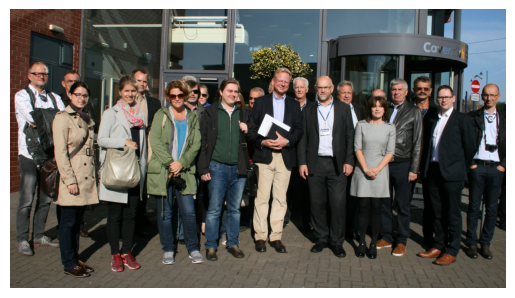

In [32]:
img = Image.open(df_copy.loc[0, "image_path"])

question = df_copy.loc[0, "question"]

print(question)
print(df_copy.loc[0, "answer"])
plt.imshow(img)
plt.axis("off")
plt.show()

In [33]:
inputs = processor(
    text = [question],
    images = [img],
    return_tensors = "pt",
    padding = True
)

In [34]:
print(inputs.keys())


KeysView({'input_ids': tensor([[49406,  9421,   536,  3651,  2097,  1047,   631,  3309,  6116,   537,
           637,  8512,  7286,   320,  3934,   267,   997,   533,   783,   320,
          2688,  2533,   530,   518,  1771,   593, 11731,  5706,   541,  1409,
          4426,  3309,   320,  3801,   269, 49407]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]), 'pixel_values': tensor([[[[-1.1499, -1.0915, -1.0769,  ..., -0.4200, -0.4200, -0.4054],
          [-1.0477, -1.1061, -1.1499,  ..., -0.4346, -0.4346, -0.3908],
          [-1.0331, -1.0331, -1.0039,  ..., -0.4200, -0.4200, -0.3908],
          ...,
          [-0.2886, -0.2886, -0.3908,  ..., -0.3616, -0.3616, -0.4492],
          [-0.2448, -0.2302, -0.2594,  ..., -0.3032, -0.3032, -0.4492],
          [-0.2010, -0.2594, -0.2740,  ..., -0.2886, -0.2594, -0.4346]],

         [[-1.0617, -0.9717, -0.9267,  ...,  0.0638,  0.0638,  0.1389],
  

In [35]:
print("Input IDs : ", inputs["input_ids"].shape)

print("Attention Mask : ", inputs["attention_mask"].shape)

print("Pixel Values : ", inputs["pixel_values"].shape)

Input IDs :  torch.Size([1, 36])
Attention Mask :  torch.Size([1, 36])
Pixel Values :  torch.Size([1, 3, 224, 224])


In [36]:
print("Number of Images : ", inputs["pixel_values"].shape[0])

print("Image Dimensions : ", inputs["pixel_values"].shape[2:])

print("Number of Questions : ", inputs["input_ids"].shape[0])

Number of Images :  1
Image Dimensions :  torch.Size([224, 224])
Number of Questions :  1



## Inserting our data into the Trained Model and Embedding

In [37]:
outputs = model(**inputs)

In [38]:
print(type(outputs))
print(outputs)

image_embeddings = outputs.image_embeds
text_embeddings = outputs.text_embeds

print("Image Embeddings : ", image_embeddings.shape)
print("Txt Embeddings : ", text_embeddings.shape)

<class 'transformers.models.clip.modeling_clip.CLIPOutput'>
CLIPOutput(loss=None, logits_per_image=tensor([[24.9441]], grad_fn=<TBackward0>), logits_per_text=tensor([[24.9441]], grad_fn=<MulBackward0>), text_embeds=tensor([[ 3.2628e-02,  4.9687e-02, -1.3122e-02, -1.4079e-02, -6.5269e-04,
          2.0526e-02,  2.9342e-03, -2.3212e-02,  2.8379e-02, -1.3278e-02,
         -3.9909e-02,  2.0234e-02,  2.3194e-02, -4.0306e-02,  3.3635e-02,
          4.6909e-03, -2.4745e-02,  5.4489e-02, -4.5275e-02,  6.1418e-03,
          3.9217e-02,  2.5696e-02,  1.0560e-02, -4.6132e-02, -9.8726e-03,
          4.2936e-02, -7.0625e-03,  1.0134e-02,  4.8862e-03, -6.7606e-03,
          2.3070e-02, -7.6378e-03,  9.7231e-03,  9.8283e-03, -6.2060e-02,
         -4.7805e-02, -5.4926e-02, -1.3496e-02, -1.8386e-02, -1.4114e-02,
          3.7198e-02, -1.0014e-02, -4.6173e-02, -6.6673e-03,  8.1620e-03,
          2.1480e-02, -1.8551e-02,  6.9215e-02,  9.2644e-04, -1.0169e-02,
          1.6711e-02,  5.2828e-02, -5.2080e-0

In [39]:
torch.save({
    "image_embeddings" : image_embeddings,
    "text_embeddings" : text_embeddings
}, "corevquembeddings.pt")

In [40]:
print("first 10 image embedding values : ")
print(image_embeddings[0][:10])

print("\n first 10 text embedding values : ")
print(text_embeddings[0][:10])

first 10 image embedding values : 
tensor([-0.0202,  0.0087,  0.0087, -0.0174,  0.0095,  0.0086, -0.0213, -0.0425,
         0.0144,  0.0325], grad_fn=<SliceBackward0>)

 first 10 text embedding values : 
tensor([ 0.0326,  0.0497, -0.0131, -0.0141, -0.0007,  0.0205,  0.0029, -0.0232,
         0.0284, -0.0133], grad_fn=<SliceBackward0>)


## Loading the main data top to down

In [41]:
import torch
from PIL import Image
from tqdm import tqdm

model.eval()

image_embeddings_list = []
text_embeddings_list = []

batch_size = 8

for i in tqdm(range(0, len(df_copy), batch_size)):
    
    batch = df_copy.iloc[i:i+batch_size]
    batch_images = []
    
    for path in batch["image_path"]:
        img = Image.open(path).convert("RGB")
        batch_images.append(img)
        
    batch_questions = batch["question"].tolist()
    
    inputs = processor(
        text = batch_questions,
        images = batch_images,
        return_tensors = "pt",
        padding = True,
        truncation = True
    )
    
    with torch.no_grad():
        outputs = model(**inputs)
        
    image_embeddings_list.append(outputs.image_embeds.cpu())
    text_embeddings_list.append(outputs.text_embeds.cpu())
    
    for img in batch_images:
        img.close
    

100%|██████████| 701/701 [24:10<00:00,  2.07s/it]


In [42]:
print("Number of Images : ", len(batch_images))
print("First Image :", batch_images[0])
print("Image Dimensions: ", batch_images[0].size)

Number of Images :  8
First Image : <PIL.Image.Image image mode=RGB size=640x449 at 0x21BD65BFD10>
Image Dimensions:  (640, 449)


In [43]:
image_embedd = torch.cat(image_embeddings_list, dim = 0)
text_embedd = torch.cat(text_embeddings_list, dim = 0)

print("image embedd : ", image_embedd.shape)
print("text embedd : ", text_embedd.shape)

image embedd :  torch.Size([5608, 512])
text embedd :  torch.Size([5608, 512])


In [44]:
image_embeddings

tensor([[-2.0248e-02,  8.6965e-03,  8.7046e-03, -1.7389e-02,  9.5377e-03,
          8.5553e-03, -2.1291e-02, -4.2506e-02,  1.4384e-02,  3.2466e-02,
         -7.9639e-03, -1.2644e-02, -3.1079e-02,  1.0393e-02,  1.7582e-02,
          1.1402e-03,  6.0300e-02,  3.7712e-02,  2.7971e-02,  2.7797e-03,
          1.0907e-01,  1.1696e-02,  2.9939e-02,  5.8020e-02,  5.5894e-02,
          1.1873e-02, -2.5405e-02, -4.6882e-03, -1.0260e-02,  4.1955e-02,
         -1.1888e-02, -2.7351e-02,  2.3404e-02, -8.6154e-03, -3.6965e-02,
          1.6732e-02, -4.8581e-03,  1.0598e-02, -2.2456e-02, -1.6350e-01,
          7.5942e-03, -2.0782e-02, -2.8365e-02,  1.6063e-02,  4.4363e-02,
         -1.4689e-01,  2.3562e-02,  3.2964e-02, -7.2130e-02, -1.1801e-02,
          3.9306e-02, -2.4800e-03,  2.5593e-03, -6.1069e-03, -6.4924e-02,
          1.7097e-02,  2.6169e-02, -1.9689e-03, -1.4924e-02, -6.2730e-03,
          7.1993e-02,  2.2703e-02,  2.4573e-03,  2.7364e-02, -8.0654e-03,
         -8.7883e-03,  2.4690e-02, -5.

In [45]:
torch.save({
    "total_image_embedd" : image_embedd,
    "total_text_embedd" : text_embedd
}, "corevquembeddings.pt")

In [46]:
X = torch.cat([image_embedd, text_embedd], dim = 1)

print(X.shape)

torch.Size([5608, 1024])


In [47]:
Y = df_copy["answer"]

Y.head()

0    1
1    1
2    0
3    0
4    0
Name: answer, dtype: int64

## Training and Testing the Main data

In [48]:
from sklearn.model_selection import train_test_split

done = train_test_split

X_train, X_test, Y_train, Y_test = done(
    X,
    Y,
    test_size = 0.10,
    random_state = 42,
    shuffle = True,
    stratify = Y
)

In [49]:
Y_test.value_counts()

answer
0    404
1    157
Name: count, dtype: int64

## Importing Necessary Libraries and Applicable Models

In [50]:
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report, f1_score

from sklearn.linear_model import LogisticRegression

from sklearn.naive_bayes import GaussianNB

from sklearn.tree import DecisionTreeClassifier

from sklearn.svm import SVC

from sklearn.neighbors import KNeighborsClassifier

import warnings

warnings.filterwarnings("ignore")


## Testing Phase

### Logistic regression

In [51]:
classifier = LogisticRegression(max_iter = 100)

classifier.fit(X_train.numpy(), Y_train.to_numpy())

Y_pred_regress = classifier.predict(X_test.numpy())

In [52]:
print(type(X_train))
print(type(Y_train))
print(classifier.n_iter_)
print(classifier.max_iter)
print(classifier.solver)

<class 'torch.Tensor'>
<class 'pandas.Series'>
[31]
100
lbfgs


In [53]:
accuracy_score(Y_test, Y_pred_regress)
classification_report(Y_test, Y_pred_regress)
confusion_matrix(Y_test, Y_pred_regress)
print(classification_report(Y_test, Y_pred_regress))

print(confusion_matrix(Y_test, Y_pred_regress))

              precision    recall  f1-score   support

           0       0.78      0.89      0.83       404
           1       0.56      0.35      0.43       157

    accuracy                           0.74       561
   macro avg       0.67      0.62      0.63       561
weighted avg       0.72      0.74      0.72       561

[[361  43]
 [102  55]]


In [54]:
print(Y_train)
print(Y_test)

2570    1
846     1
3589    0
1287    1
3884    1
       ..
4000    0
4548    1
2015    1
2856    0
1987    0
Name: answer, Length: 5047, dtype: int64
4466    0
1172    0
2693    0
4178    0
1945    1
       ..
1629    0
1903    0
4908    0
5373    0
1137    1
Name: answer, Length: 561, dtype: int64


### SVM

In [55]:
classifier = SVC(kernel = "linear")

classifier.fit(X_train, Y_train)
Y_pred_svc = classifier.predict(X_test)

In [56]:
accuracy_score(Y_test, Y_pred_svc)
print(confusion_matrix(Y_test, Y_pred_svc))
print(classification_report(Y_test, Y_pred_svc))

[[353  51]
 [ 86  71]]
              precision    recall  f1-score   support

           0       0.80      0.87      0.84       404
           1       0.58      0.45      0.51       157

    accuracy                           0.76       561
   macro avg       0.69      0.66      0.67       561
weighted avg       0.74      0.76      0.75       561



### KNN

In [57]:
classifier = KNeighborsClassifier(
    n_neighbors=11,
    metric = "cosine",
    weights = "distance"
)

classifier.fit(X_train, Y_train)

Y_pred_knn = classifier.predict(X_test)



In [58]:
accuracy_score(Y_test, Y_pred_knn)
print(confusion_matrix(Y_test, Y_pred_knn))
print(classification_report(Y_test, Y_pred_knn))

[[349  55]
 [110  47]]
              precision    recall  f1-score   support

           0       0.76      0.86      0.81       404
           1       0.46      0.30      0.36       157

    accuracy                           0.71       561
   macro avg       0.61      0.58      0.59       561
weighted avg       0.68      0.71      0.68       561



### Decision Tree

In [59]:
classifier = DecisionTreeClassifier(
    criterion = "gini",
    max_depth = 5,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state = 42
)

classifier.fit(X_train.numpy(), Y_train)
Y_pred_tree = classifier.predict(X_test.numpy())



In [60]:
accuracy_score(Y_test, Y_pred_tree)
print(confusion_matrix(Y_test, Y_pred_tree))
print(classification_report(Y_test, Y_pred_tree))

[[368  36]
 [131  26]]
              precision    recall  f1-score   support

           0       0.74      0.91      0.82       404
           1       0.42      0.17      0.24       157

    accuracy                           0.70       561
   macro avg       0.58      0.54      0.53       561
weighted avg       0.65      0.70      0.65       561



### Gaussian Naive Baise

In [61]:
classifier = GaussianNB()

classifier.fit(X_train.numpy(), Y_train.to_numpy())
Y_pred_nb = classifier.predict(X_test.numpy())

In [62]:
print(accuracy_score(Y_test, Y_pred_nb))
print(confusion_matrix(Y_test, Y_pred_nb))
print(classification_report(Y_test, Y_pred_nb))

0.6702317290552585
[[267 137]
 [ 48 109]]
              precision    recall  f1-score   support

           0       0.85      0.66      0.74       404
           1       0.44      0.69      0.54       157

    accuracy                           0.67       561
   macro avg       0.65      0.68      0.64       561
weighted avg       0.73      0.67      0.69       561



In [63]:
from sklearn.ensemble import RandomForestClassifier

# Creating the model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Training
rf_model.fit(X_train, Y_train)

# Prediction
rf_predictions = rf_model.predict(X_test)

In [64]:
print(accuracy_score(Y_test, rf_predictions))
print(confusion_matrix(Y_test, rf_predictions))
print(classification_report(Y_test, rf_predictions))

0.7094474153297683
[[334  70]
 [ 93  64]]
              precision    recall  f1-score   support

           0       0.78      0.83      0.80       404
           1       0.48      0.41      0.44       157

    accuracy                           0.71       561
   macro avg       0.63      0.62      0.62       561
weighted avg       0.70      0.71      0.70       561



In [65]:
negative = (Y_train == 0).sum()
positive = (Y_train == 1).sum()

print(negative)

from xgboost import XGBClassifier

3638


In [66]:

# Calculate class imbalance from training data
negative = (Y_train == 0).sum()
positive = (Y_train == 1).sum()

# Create model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=negative / positive,
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Training
xgb_model.fit(X_train, Y_train)

# Prediction
xgb_predictions = xgb_model.predict(X_test)





In [67]:
print(accuracy_score(Y_test, xgb_predictions))
print(confusion_matrix(Y_test, xgb_predictions))
print(classification_report(Y_test, xgb_predictions))


0.7201426024955436
[[307  97]
 [ 60  97]]
              precision    recall  f1-score   support

           0       0.84      0.76      0.80       404
           1       0.50      0.62      0.55       157

    accuracy                           0.72       561
   macro avg       0.67      0.69      0.67       561
weighted avg       0.74      0.72      0.73       561



# Overall Comparison

In [68]:
result = []

models = {
    "LogisticRegression" : LogisticRegression(max_iter = 100),
    "KNN" : KNeighborsClassifier(n_neighbors = 11, metric = "cosine", weights = "distance"),
    "SVM" : SVC(kernel = "linear"),
    "Tree" : DecisionTreeClassifier(),
    "GNB" : GaussianNB(),
    "Random Forest" : RandomForestClassifier(n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1),
    "XG Boost" : XGBClassifier(n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=negative / positive,
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )
}

In [69]:

for name, model in models.items():
    model.fit(X_train, Y_train)
    Y_pred = model.predict(X_test)
    accuracy = accuracy_score(Y_test, Y_pred)
    f1 = f1_score(Y_test, Y_pred)
    result.append({
        "Model" : name,
        "Accuracy" : accuracy,
        "F1 Score" : f1
    })
    
final_result = pd.DataFrame(result)
print(final_result)

                Model  Accuracy  F1 Score
0  LogisticRegression  0.741533  0.431373
1                 KNN  0.705882  0.362934
2                 SVM  0.755793  0.508961
3                Tree  0.623886  0.330159
4                 GNB  0.670232  0.540943
5       Random Forest  0.709447  0.439863
6            XG Boost  0.720143  0.552707


In [70]:
import joblib

joblib.dump(models["SVM"], "SVM_VLM.pkl")

['SVM_VLM.pkl']

In [71]:
df_copy["answer"].value_counts()

answer
0    4042
1    1566
Name: count, dtype: int64

# End of the World